In [2]:
#libraries
%pip install econml scikit-learn pandas numpy matplotlib joblib

Note: you may need to restart the kernel to use updated packages.


In [3]:
#Import libraries and configure paths
from pathlib import Path
import warnings
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from econml.dml import CausalForestDML
import joblib

warnings.filterwarnings("ignore")

REPO_DIR = Path(
    r"C:\Users\sreer\OneDrive\Desktop\Sasi Deepika\Infotact\EconoCausal-Dynamic-Pricing-via-Double-Machine-Learning"
)

DATA_DIR = Path(
    r"C:\Users\sreer\OneDrive\Desktop\Sasi Deepika\Infotact\cleaned_data"
)

OUTPUT_DIR = REPO_DIR / "outputs" / "model_training"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Repository:", REPO_DIR)
print("Dataset:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)
print("Repository exists:", REPO_DIR.exists())
print("Dataset exists:", DATA_DIR.exists())

Repository: C:\Users\sreer\OneDrive\Desktop\Sasi Deepika\Infotact\EconoCausal-Dynamic-Pricing-via-Double-Machine-Learning
Dataset: C:\Users\sreer\OneDrive\Desktop\Sasi Deepika\Infotact\cleaned_data
Output directory: C:\Users\sreer\OneDrive\Desktop\Sasi Deepika\Infotact\EconoCausal-Dynamic-Pricing-via-Double-Machine-Learning\outputs\model_training
Repository exists: True
Dataset exists: True


In [4]:
#Load the cleaned datasets
transactions_path = DATA_DIR / "transactions_clean.csv"
promotions_path = DATA_DIR / "promotions_clean.csv"

if not transactions_path.exists():
    raise FileNotFoundError(f"Missing file: {transactions_path}")

if not promotions_path.exists():
    raise FileNotFoundError(f"Missing file: {promotions_path}")

transactions = pd.read_csv(transactions_path)
promotions = pd.read_csv(promotions_path)

print("Transactions shape:", transactions.shape)
print("Promotions shape:", promotions.shape)

print("\nTransaction columns:")
print(transactions.columns.tolist())

print("\nPromotion columns:")
print(promotions.columns.tolist())

Transactions shape: (2595732, 12)
Promotions shape: (36786524, 5)

Transaction columns:
['household_key', 'BASKET_ID', 'DAY', 'PRODUCT_ID', 'QUANTITY', 'SALES_VALUE', 'STORE_ID', 'RETAIL_DISC', 'TRANS_TIME', 'WEEK_NO', 'COUPON_DISC', 'COUPON_MATCH_DISC']

Promotion columns:
['PRODUCT_ID', 'STORE_ID', 'WEEK_NO', 'display', 'mailer']


In [5]:
#Inspect columns before defining the casual variables
print("TRANSACTIONS SAMPLE")
display(transactions.head())

print("PROMOTIONS SAMPLE")
display(promotions.head())

print("\nTransaction data types:")
display(transactions.dtypes.to_frame("data_type"))

print("\nPromotion data types:")
display(promotions.dtypes.to_frame("data_type"))

TRANSACTIONS SAMPLE


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0


PROMOTIONS SAMPLE


,PRODUCT_ID,STORE_ID,WEEK_NO,display,mailer
0,26190,286,70,0,A
1,26190,288,70,0,A
2,26190,289,70,0,A
3,26190,292,70,0,A
4,26190,293,70,0,A



Transaction data types:


,data_type
household_key,int64
BASKET_ID,int64
DAY,int64
PRODUCT_ID,int64
QUANTITY,int64
SALES_VALUE,float64
STORE_ID,int64
RETAIL_DISC,float64
TRANS_TIME,int64
WEEK_NO,int64



Promotion data types:


,data_type
PRODUCT_ID,int64
STORE_ID,int64
WEEK_NO,int64
display,object
mailer,object


In [6]:
#Identify candidate treatment and outcome columns
def find_candidates(df, keywords):
    return [
        col for col in df.columns
        if any(keyword in col.lower() for keyword in keywords)
    ]

print("Possible outcome columns:")
print(find_candidates(
    transactions,
    ["sales", "quantity", "spend", "revenue", "amount", "units"]
))

print("\nPossible treatment columns:")
print(find_candidates(
    promotions,
    ["price", "discount", "promo", "promotion", "treatment", "exposure"]
))

print("\nPossible join keys:")
print("Transactions:", find_candidates(
    transactions, ["product_id", "household_key", "store_id", "week", "day"]
))
print("Promotions:", find_candidates(
    promotions, ["product_id", "store_id", "week", "day", "campaign"]
))

Possible outcome columns:
['QUANTITY', 'SALES_VALUE']

Possible treatment columns:
[]

Possible join keys:
Transactions: ['household_key', 'DAY', 'PRODUCT_ID', 'STORE_ID', 'WEEK_NO']
Promotions: ['PRODUCT_ID', 'STORE_ID', 'WEEK_NO']


In [7]:
#Inspect promotion values and duplicate keys
promo_keys = ["PRODUCT_ID", "STORE_ID", "WEEK_NO"]

print("Promotion missing values:")
display(promotions.isnull().sum())

print("\nDisplay values:")
display(promotions["display"].value_counts(dropna=False).head(20))

print("\nMailer values:")
display(promotions["mailer"].value_counts(dropna=False).head(20))

print("\nUnique promotion keys:")
print(promotions[promo_keys].drop_duplicates().shape[0])

print("\nTotal promotion rows:", len(promotions))
print("Duplicate promotion keys:",
      promotions.duplicated(subset=promo_keys).sum())

Promotion missing values:


PRODUCT_ID    0
STORE_ID      0
WEEK_NO       0
display       0
mailer        0
dtype: int64


Display values:


display
0    21038745
9     2699467
5     2575289
7     2362118
3     2073738
6     1816021
2     1812840
1     1102141
A      713180
4      592985
Name: count, dtype: int64


Mailer values:


mailer
A    17106789
0    11534183
D     4467453
H     1560395
F     1077549
J      306924
L      301327
C      291059
X      120823
Z       19453
P         569
Name: count, dtype: int64


Unique promotion keys:
36771279

Total promotion rows: 36786524
Duplicate promotion keys: 15245


In [8]:
#prepare promotion data
# First verify that both columns contain numeric values.
for col in ["display", "mailer"]:
    print(f"\n{col} data type:", promotions[col].dtype)
    print("Sample values:", promotions[col].dropna().unique()[:20])


display data type: object
Sample values: ['0' '5' '1' '4' '3' '9' 'A' '6' '7' '2']

mailer data type: object
Sample values: ['A' '0' 'H' 'D' 'F' 'J' 'C' 'L' 'X' 'P' 'Z']


In [9]:
promo = promotions.copy()

for col in ["display", "mailer"]:
    print(f"\n{col} value counts:")
    display(promo[col].value_counts(dropna=False).head(30))

    print(f"\n{col} unique values:")
    print(promo[col].dropna().unique()[:30])

    print(f"\n{col} data type:")
    print(promo[col].dtype)


display value counts:


display
0    21038745
9     2699467
5     2575289
7     2362118
3     2073738
6     1816021
2     1812840
1     1102141
A      713180
4      592985
Name: count, dtype: int64


display unique values:
['0' '5' '1' '4' '3' '9' 'A' '6' '7' '2']

display data type:
object

mailer value counts:


mailer
A    17106789
0    11534183
D     4467453
H     1560395
F     1077549
J      306924
L      301327
C      291059
X      120823
Z       19453
P         569
Name: count, dtype: int64


mailer unique values:
['A' '0' 'H' 'D' 'F' 'J' 'C' 'L' 'X' 'P' 'Z']

mailer data type:
object


In [15]:
#Create one record per product, store and week
import pandas as pd

join_keys = ["PRODUCT_ID", "STORE_ID", "WEEK_NO"]

promo_small = promo_filtered.copy()

for col in join_keys:
    promo_small[col] = promo_small[col].astype("string")

# Normalize category values
for col in ["display", "mailer"]:
    promo_small[col] = (
        promo_small[col].astype("string").str.strip()
    )

# Create exposure indicators:
# 1 = at least one nonzero category; 0 = category 0 only
promo_small["display_exposed"] = (
    promo_small["display"].notna()
    & promo_small["display"].ne("0")
).astype("int8")

promo_small["mailer_exposed"] = (
    promo_small["mailer"].notna()
    & promo_small["mailer"].ne("0")
).astype("int8")

# Combine multiple categories for each join key
promo_agg = (
    promo_small.groupby(join_keys, as_index=False)
    .agg({
        "display_exposed": "max",
        "mailer_exposed": "max"
    })
)

print("Aggregated promotions:", promo_agg.shape)
print("Duplicate keys:",
      promo_agg.duplicated(subset=join_keys).sum())

display(promo_agg.head())

Aggregated promotions: (483320, 5)
Duplicate keys: 0


,PRODUCT_ID,STORE_ID,WEEK_NO,display_exposed,mailer_exposed
0,1000050,288,27,1,1
1,1000050,289,51,1,1
2,1000050,289,59,1,1
3,1000050,292,27,1,1
4,1000050,292,37,0,1


In [16]:
#Join transactions with promotions
for col in join_keys:
    transactions[col] = transactions[col].astype("string")

merged_df = transactions.merge(
    promo_agg,
    on=join_keys,
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Original transactions:", len(transactions))
print("Merged transactions:", len(merged_df))

display(merged_df["_merge"].value_counts())

assert len(merged_df) == len(transactions), (
    "Unexpected row multiplication during join."
)

Original transactions: 2595732
Merged transactions: 2595732


_merge
left_only     2031958
both           563774
right_only          0
Name: count, dtype: int64

In [17]:
#Check treatment variation
print("Display exposure:")
display(merged_df["display_exposed"].value_counts(dropna=False))

print("\nMailer exposure:")
display(merged_df["mailer_exposed"].value_counts(dropna=False))

print("\nUnmatched transaction rows:",
      merged_df["_merge"].eq("left_only").sum())

Display exposure:


display_exposed
NaN    2031958
0.0     290123
1.0     273651
Name: count, dtype: int64


Mailer exposure:


mailer_exposed
NaN    2031958
1.0     414150
0.0     149624
Name: count, dtype: int64


Unmatched transaction rows: 2031958


In [18]:
#Check whether the unmatched rows are expeted
# Check the data types of the merge keys
print("Transaction key types:")
print(transactions[join_keys].dtypes)

print("\nPromotion key types:")
print(promo_agg[join_keys].dtypes)

# Inspect unmatched transaction rows
unmatched = merged_df[merged_df["_merge"] == "left_only"]

display(unmatched[join_keys + ["SALES_VALUE", "QUANTITY"]].head(10))

# Compare key ranges
print("\nTransaction key ranges:")
display(transactions[join_keys].describe())

print("\nPromotion key ranges:")
display(promo_agg[join_keys].describe())

Transaction key types:
PRODUCT_ID    string[python]
STORE_ID      string[python]
WEEK_NO       string[python]
dtype: object

Promotion key types:
PRODUCT_ID    string[python]
STORE_ID      string[python]
WEEK_NO       string[python]
dtype: object


,PRODUCT_ID,STORE_ID,WEEK_NO,SALES_VALUE,QUANTITY
0,1004906,364,1,1.39,1
1,1033142,364,1,0.82,1
2,1036325,364,1,0.99,1
3,1082185,364,1,1.21,1
4,8160430,364,1,1.50,1
5,826249,364,1,1.98,2
6,1043142,364,1,1.57,1
7,1085983,364,1,2.99,1
8,1102651,364,1,1.89,1
9,6423775,364,1,2.00,1



Transaction key ranges:


,PRODUCT_ID,STORE_ID,WEEK_NO
count,2595732,2595732,2595732
unique,92339,582,102
top,1082185,367,92
freq,29778,75573,33126



Promotion key ranges:


,PRODUCT_ID,STORE_ID,WEEK_NO
count,483320,483320,483320
unique,22153,115,93
top,995242,367,68
freq,3216,10528,7776


In [19]:
#Identify which join key is causing the mismatch
# Compare unique values for each key
for col in join_keys:
    tx_values = set(transactions[col].dropna().unique())
    promo_values = set(promo_agg[col].dropna().unique())

    common = tx_values.intersection(promo_values)

    print(f"\n{col}")
    print("Unique transaction values:", len(tx_values))
    print("Unique promotion values:", len(promo_values))
    print("Common values:", len(common))
    print("Transaction values with no overlap:", len(tx_values - promo_values))


PRODUCT_ID
Unique transaction values: 92339
Unique promotion values: 22153
Common values: 22153
Transaction values with no overlap: 70186

STORE_ID
Unique transaction values: 582
Unique promotion values: 115
Common values: 115
Transaction values with no overlap: 467

WEEK_NO
Unique transaction values: 102
Unique promotion values: 93
Common values: 93
Transaction values with no overlap: 9


In [20]:
#Check the overlap of complete product–store–week combinations
# Get unique transaction combinations
transaction_keys = transactions[join_keys].drop_duplicates()

# Get unique promotion combinations
promotion_keys = promo_agg[join_keys].drop_duplicates()

# Find combinations present in both datasets
matched_keys = transaction_keys.merge(
    promotion_keys,
    on=join_keys,
    how="inner"
)

print("Unique transaction combinations:", len(transaction_keys))
print("Unique promotion combinations:", len(promotion_keys))
print("Matching combinations:", len(matched_keys))
print(
    "Transaction combinations without promotion records:",
    len(transaction_keys) - len(matched_keys)
)

# Check whether unmatched rows are concentrated in certain weeks
unmatched = merged_df[merged_df["_merge"] == "left_only"]

print("\nUnmatched transactions by week:")
display(
    unmatched["WEEK_NO"]
    .value_counts()
    .sort_index()
    .head(20)
)

print("\nMatched transactions by week:")
display(
    merged_df.loc[merged_df["_merge"] == "both", "WEEK_NO"]
    .value_counts()
    .sort_index()
    .head(20)
)

Unique transaction combinations: 2370784
Unique promotion combinations: 483320
Matching combinations: 483320
Transaction combinations without promotion records: 1887464

Unmatched transactions by week:


WEEK_NO
1       1881
10     10724
100    22917
101    21346
102    22423
11     12426
12     13877
13     14343
14     16233
15     18163
16     19666
17     20909
18     19940
19     18962
2       3675
20     21691
21     21423
22     20366
23     19127
24     21817
Name: count, dtype: Int64


Matched transactions by week:


WEEK_NO
10     2819
100    5985
101    5267
11     4280
12     3635
13     4291
14     5651
15     5427
16     7193
17     5416
18     5592
19     5272
20     8181
21     5588
22     5428
23     6031
24     6045
25     7303
26     5638
27     6319
Name: count, dtype: Int64

In [21]:
#Aggregate transactions
import pandas as pd
import numpy as np
from pathlib import Path

join_keys = ["PRODUCT_ID", "STORE_ID", "WEEK_NO"]

# Aggregate transaction outcomes to the treatment-assignment level
sales_agg = (
    transactions
    .groupby(join_keys, as_index=False)
    .agg(
        SALES_VALUE=("SALES_VALUE", "sum"),
        QUANTITY=("QUANTITY", "sum"),
        transaction_count=("BASKET_ID", "nunique")
    )
)

print("Aggregated sales shape:", sales_agg.shape)
display(sales_agg.head())

Aggregated sales shape: (2370784, 6)


,PRODUCT_ID,STORE_ID,WEEK_NO,SALES_VALUE,QUANTITY,transaction_count
0,1000002,292,100,3.11,1,1
1,1000002,292,66,5.87,1,1
2,1000002,292,67,9.16,2,2
3,1000002,292,68,6.05,1,1
4,1000002,295,12,3.36,1,1


In [22]:
#Join sales with promotion exposure
model_df = sales_agg.merge(
    promo_agg,
    on=join_keys,
    how="inner",
    validate="one_to_one"
)

print("Model dataset shape:", model_df.shape)
print("\nMissing values:")
display(model_df.isnull().sum())

print("\nDisplay exposure:")
display(model_df["display_exposed"].value_counts(dropna=False))

print("\nMailer exposure:")
display(model_df["mailer_exposed"].value_counts(dropna=False))

display(model_df.head())

Model dataset shape: (483320, 8)

Missing values:


PRODUCT_ID           0
STORE_ID             0
WEEK_NO              0
SALES_VALUE          0
QUANTITY             0
transaction_count    0
display_exposed      0
mailer_exposed       0
dtype: int64


Display exposure:


display_exposed
0    246268
1    237052
Name: count, dtype: int64


Mailer exposure:


mailer_exposed
1    350188
0    133132
Name: count, dtype: int64

,PRODUCT_ID,STORE_ID,WEEK_NO,SALES_VALUE,QUANTITY,transaction_count,display_exposed,mailer_exposed
0,1000050,288,27,1.88,1,1,1,1
1,1000050,289,51,4.00,2,2,1,1
2,1000050,289,59,1.67,1,1,1,1
3,1000050,292,27,3.76,2,1,1,1
4,1000050,292,37,2.00,1,1,0,1


In [24]:
# Check whether EconML is installed
try:
    import econml
    print("EconML version:", econml.__version__)
except ImportError:
    print("EconML is not installed.")
    print("Run this in a notebook cell: %pip install econml")

EconML version: 0.17.0


In [25]:
#Prepare the first model inputs
import numpy as np
import pandas as pd

# Use only rows with observed promotion records
model_data = model_df.copy()

# Outcome: aggregated sales value
Y = model_data["SALES_VALUE"].astype(float).to_numpy()

# Treatment: whether the product was displayed
T = model_data["display_exposed"].astype(int).to_numpy()

# Effect-modifying feature: week
X = model_data[["WEEK_NO"]].astype(float).to_numpy()

# Additional observed covariate: mailer exposure
W = model_data[["mailer_exposed"]].astype(float).to_numpy()

print("Rows:", len(model_data))
print("Outcome shape:", Y.shape)
print("Treatment shape:", T.shape)
print("X shape:", X.shape)
print("W shape:", W.shape)
print("Treatment counts:", np.unique(T, return_counts=True))

assert np.isfinite(Y).all()
assert np.isfinite(X).all()
assert np.isfinite(W).all()
assert set(np.unique(T)).issubset({0, 1})

Rows: 483320
Outcome shape: (483320,)
Treatment shape: (483320,)
X shape: (483320, 1)
W shape: (483320, 1)
Treatment counts: (array([0, 1]), array([246268, 237052]))


In [26]:
#Train the initial Causal Forest DML model
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from econml.dml import CausalForestDML

# Reproducible sample for the first training run
rng = np.random.default_rng(42)
sample_size = min(100_000, len(model_data))
sample_idx = rng.choice(len(model_data), size=sample_size, replace=False)

Y_sample = Y[sample_idx]
T_sample = T[sample_idx]
X_sample = X[sample_idx]
W_sample = W[sample_idx]

# Ensure both treatment groups are represented
print("Sample treatment counts:", np.unique(T_sample, return_counts=True))

model = CausalForestDML(
    model_y=RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=10,
        n_jobs=-1,
        random_state=42
    ),
    model_t=RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=10,
        n_jobs=-1,
        random_state=42
    ),
    discrete_treatment=True,
    n_estimators=100,
    min_samples_leaf=20,
    max_depth=None,
    cv=2,
    n_jobs=-1,
    random_state=42
)

model.fit(Y_sample, T_sample, X=X_sample, W=W_sample)

print("Initial CausalForestDML model trained successfully.")

Sample treatment counts: (array([0, 1]), array([50877, 49123]))
Initial CausalForestDML model trained successfully.


In [27]:
#Estimate and save ITEs
from pathlib import Path

output_dir = Path("outputs") / "model_training"
output_dir.mkdir(parents=True, exist_ok=True)

ite = model.effect(X_sample)

ite_results = pd.DataFrame({
    "WEEK_NO": model_data.iloc[sample_idx]["WEEK_NO"].to_numpy(),
    "display_exposed": T_sample,
    "SALES_VALUE": Y_sample,
    "estimated_display_effect": ite
})

ite_results.to_csv(output_dir / "day1_ite_estimates.csv", index=False)

summary = ite_results["estimated_display_effect"].describe()
summary.to_csv(output_dir / "day1_ite_summary.csv", header=["value"])

print("Saved ITE estimates to:", output_dir / "day1_ite_estimates.csv")
display(summary)
display(ite_results.head())

Saved ITE estimates to: outputs\model_training\day1_ite_estimates.csv


count    100000.000000
mean         -0.292494
std           0.408826
min          -1.228784
25%          -0.590450
50%          -0.237045
75%          -0.076892
max           0.892401
Name: estimated_display_effect, dtype: float64

,WEEK_NO,display_exposed,SALES_VALUE,estimated_display_effect
0,29,1,1.67,-0.311009
1,12,0,5.80,0.358791
2,90,0,2.25,-0.758025
3,39,0,1.00,0.219759
4,73,0,2.90,0.038749


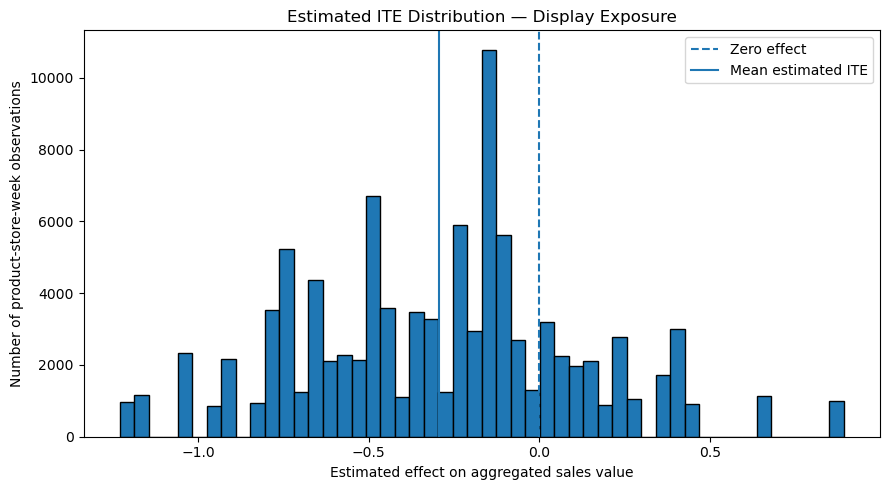

In [29]:
#ITE distribution
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("outputs") / "model_training"
output_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9, 5))
plt.hist(
    ite_results["estimated_display_effect"],
    bins=50,
    edgecolor="black"
)
plt.axvline(0, linestyle="--", linewidth=1.5, label="Zero effect")
plt.axvline(
    ite_results["estimated_display_effect"].mean(),
    linestyle="-",
    linewidth=1.5,
    label="Mean estimated ITE"
)

plt.xlabel("Estimated effect on aggregated sales value")
plt.ylabel("Number of product-store-week observations")
plt.title("Estimated ITE Distribution — Display Exposure")
plt.legend()
plt.tight_layout()

plt.savefig(
    output_dir / "ite_distribution.png",
    dpi=150
)
plt.show()

In [31]:
import json

summary_data = {
    "project": "EconoCausal",
    "day": 1,
    "model": "EconML CausalForestDML",
    "nuisance_estimators": "Random Forest",
    "treatment": "display_exposed",
    "outcome": "SALES_VALUE",
    "modeling_unit": "product-store-week",
    "sample_size": int(len(ite_results)),
    "treatment_off": int((T_sample == 0).sum()),
    "treatment_on": int((T_sample == 1).sum()),
    "ite_mean": float(ite_results["estimated_display_effect"].mean()),
    "ite_std": float(ite_results["estimated_display_effect"].std()),
    "ite_min": float(ite_results["estimated_display_effect"].min()),
    "ite_median": float(ite_results["estimated_display_effect"].median()),
    "ite_max": float(ite_results["estimated_display_effect"].max()),
    "interpretation": (
        "Exploratory estimates only; further confounding control "
        "and validation are required before causal conclusions."
    )
}

with open(output_dir / "day1_model_summary.json", "w") as f:
    json.dump(summary_data, f, indent=4)

print("Saved model summary.")
print(output_dir.resolve())

Saved model summary.
C:\Users\sreer\Downloads\outputs\model_training
